In [1]:
# ── Section 1: Setup & Load Data ──────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             RocCurveDisplay)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120

df = pd.read_csv('/kaggle/input/datasets/abbas829/telco-customer-churn-dataset/Telco-Customer-Churn.csv')

print("Shape:", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nFirst 5 rows:")
df.head()

Shape: (7043, 21)

Column names:
 ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# ── Section 2: Initial Data Inspection ───────────────────────────────────────

print("=== Data Types ===")
print(df.dtypes)

print("\n=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Target Variable Distribution ===")
print(df['Churn'].value_counts())
print("\nChurn Rate: {:.2f}%".format(df['Churn'].value_counts(normalize=True)['Yes'] * 100))

# TotalCharges comes as object
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("\n=== Missing after TotalCharges fix ===")
print(df[df['TotalCharges'].isnull()])

=== Data Types ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

=== Missing Values ===
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
Pap

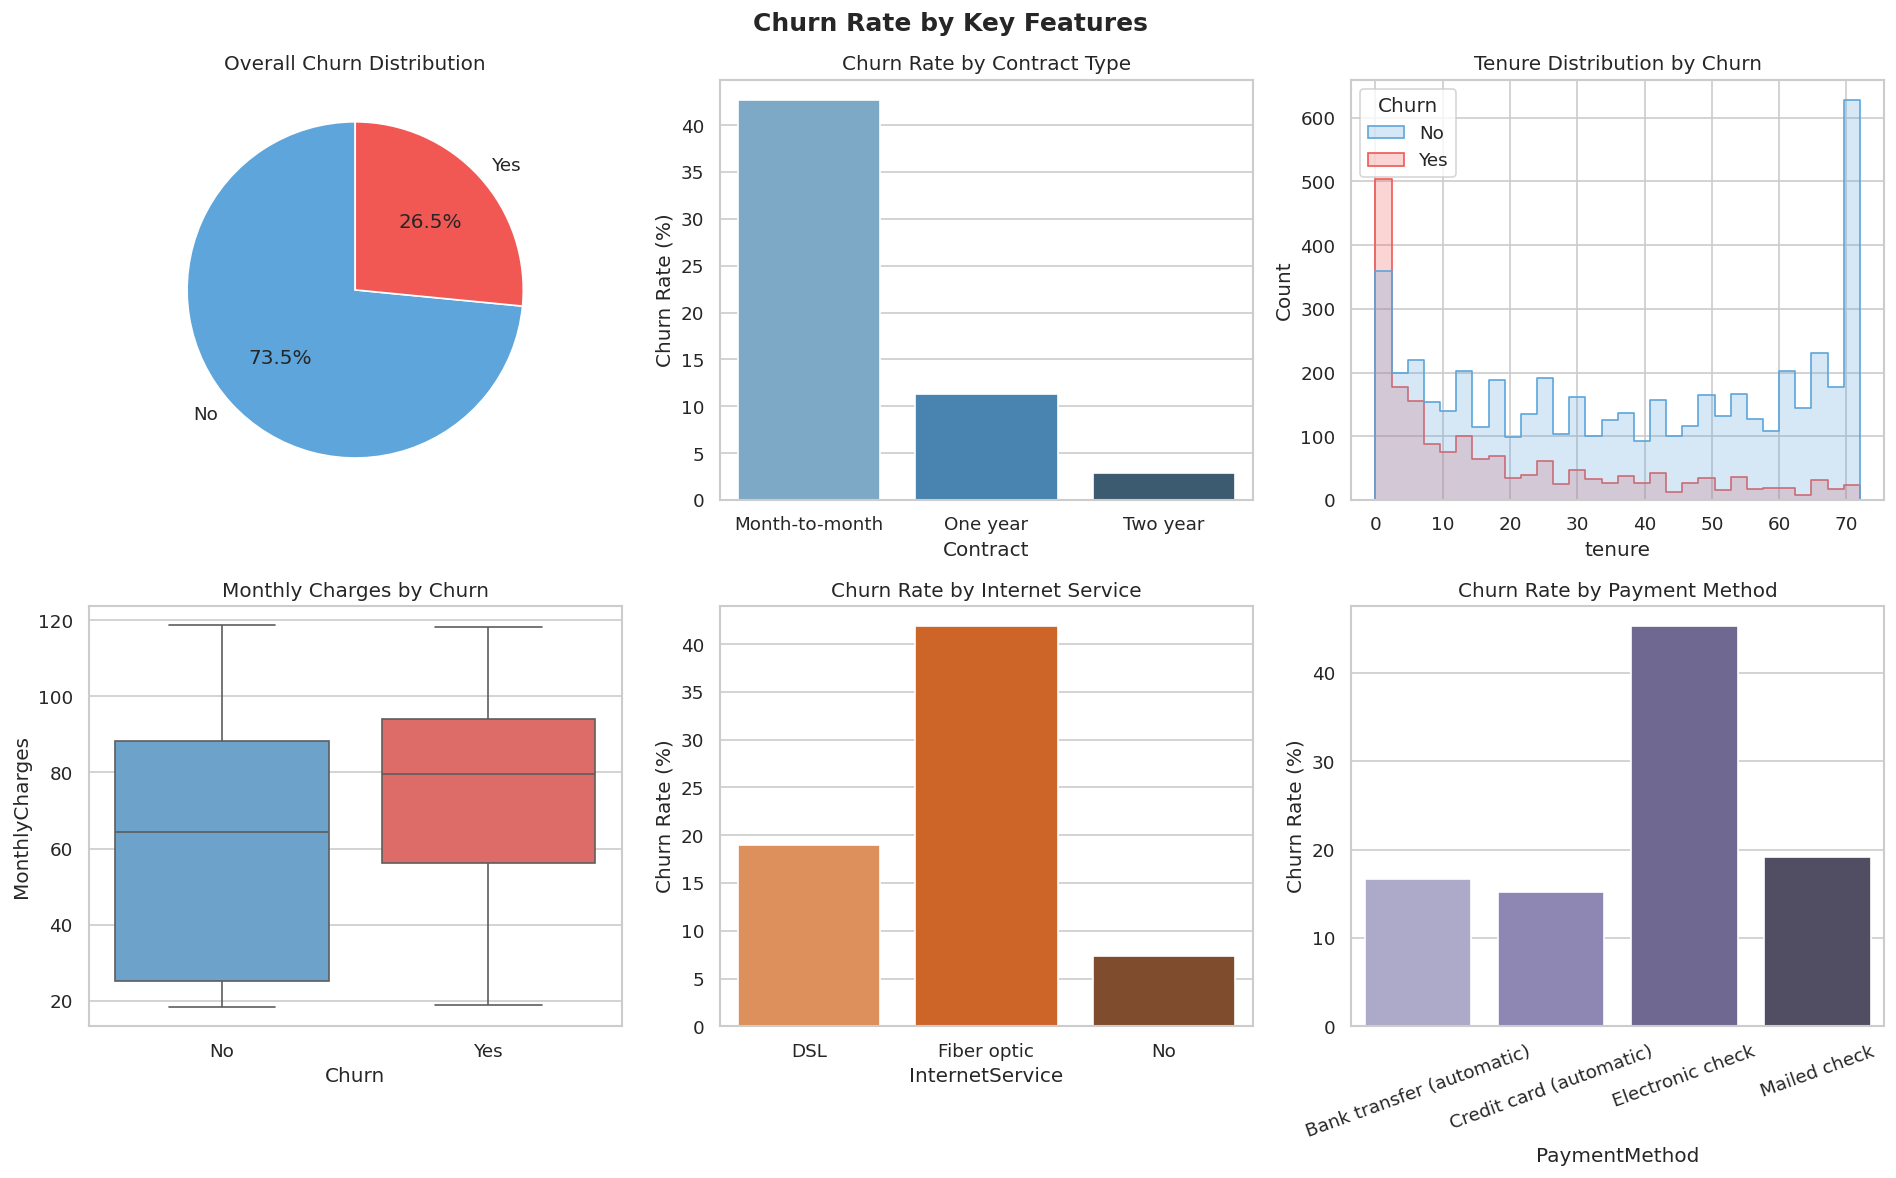

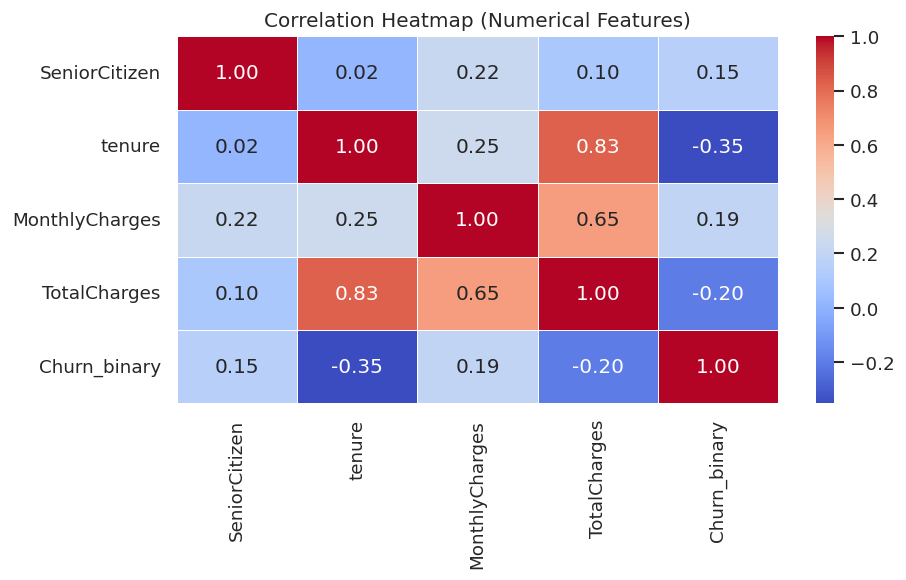

In [3]:
# ── Section 3: EDA ───────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Churn Rate by Key Features', fontsize=15, fontweight='bold')

# 1. Churn distribution
churn_counts = df['Churn'].value_counts()
axes[0,0].pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%',
              colors=['#5DA5DA','#F15854'], startangle=90)
axes[0,0].set_title('Overall Churn Distribution')

# 2. Contract type vs Churn
ct = df.groupby('Contract')['Churn'].apply(lambda x: (x=='Yes').mean() * 100).reset_index()
sns.barplot(data=ct, x='Contract', y='Churn', ax=axes[0,1], palette='Blues_d')
axes[0,1].set_title('Churn Rate by Contract Type')
axes[0,1].set_ylabel('Churn Rate (%)')

# 3. Tenure distribution
df['Churn_binary'] = (df['Churn'] == 'Yes').astype(int)
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, ax=axes[0,2],
             element='step', palette={'Yes':'#F15854','No':'#5DA5DA'})
axes[0,2].set_title('Tenure Distribution by Churn')

# 4. Monthly charges
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1,0],
            palette={'Yes':'#F15854','No':'#5DA5DA'})
axes[1,0].set_title('Monthly Charges by Churn')

# 5. Internet service vs churn
isp = df.groupby('InternetService')['Churn'].apply(lambda x: (x=='Yes').mean() * 100).reset_index()
sns.barplot(data=isp, x='InternetService', y='Churn', ax=axes[1,1], palette='Oranges_d')
axes[1,1].set_title('Churn Rate by Internet Service')
axes[1,1].set_ylabel('Churn Rate (%)')

# 6. Payment method vs churn
pm = df.groupby('PaymentMethod')['Churn'].apply(lambda x: (x=='Yes').mean() * 100).reset_index()
sns.barplot(data=pm, x='PaymentMethod', y='Churn', ax=axes[1,2], palette='Purples_d')
axes[1,2].set_title('Churn Rate by Payment Method')
axes[1,2].tick_params(axis='x', rotation=20)
axes[1,2].set_ylabel('Churn Rate (%)')

plt.tight_layout()
plt.show()

# Correlation heatmap (numeric only)
plt.figure(figsize=(8, 5))
num_cols = df.select_dtypes(include=np.number).columns.tolist()
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap (Numerical Features)')
plt.tight_layout()
plt.show()

In [4]:
# ── Section 4: Data Cleaning & Preprocessing ─────────────────────────────────

# Drop customerID (not useful) and fill missing TotalCharges
df.drop(columns=['customerID'], inplace=True)
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# Convert SeniorCitizen from 0/1 to No/Yes for consistency
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# Encode binary target
df['Churn_binary'] = (df['Churn'] == 'Yes').astype(int)
df.drop(columns=['Churn'], inplace=True)

# Separate columns by type
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)

# Label encode all categorical columns
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

print("\nDataframe after encoding:")
df.head()

Categorical columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical columns: ['tenure', 'MonthlyCharges', 'TotalCharges']

Dataframe after encoding:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn_binary
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [5]:
# ── Section 5: Feature Engineering ───────────────────────────────────────────

# Tenure groups (new customers, mid, long-term)
df['tenure_group'] = pd.cut(df['tenure'], bins=[0, 12, 36, 72],
                             labels=['new', 'mid', 'long'])
df['tenure_group'] = LabelEncoder().fit_transform(df['tenure_group'].astype(str))

# Charge per month ratio (total value delivered vs monthly cost)
df['charge_ratio'] = df['TotalCharges'] / (df['MonthlyCharges'] + 1)

# Number of services subscribed
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_services'] = df[service_cols].sum(axis=1)

print("New features added: tenure_group, charge_ratio, num_services")
print("\nFinal shape:", df.shape)
df[['tenure_group', 'charge_ratio', 'num_services', 'Churn_binary']].describe()

New features added: tenure_group, charge_ratio, num_services

Final shape: (7043, 23)


,tenure_group,charge_ratio,num_services,Churn_binary
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.193100,31.811706,7.219509,0.265370
std,1.275097,24.148200,3.349741,0.441561
min,0.000000,0.949495,1.000000,0.000000
25%,0.000000,8.642594,5.000000,0.000000
50%,1.000000,28.246729,7.000000,0.000000
75%,3.000000,54.318129,9.000000,1.000000
max,3.000000,75.518072,15.000000,1.000000


In [6]:
# ── Section 6: Train/Test Split & Scaling ────────────────────────────────────

X = df.drop(columns=['Churn_binary'])
y = df['Churn_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Training set: {X_train_scaled.shape}")
print(f"Test set:     {X_test_scaled.shape}")
print(f"\nChurn rate in train: {y_train.mean()*100:.2f}%")
print(f"Churn rate in test:  {y_test.mean()*100:.2f}%")

Training set: (5634, 22)
Test set:     (1409, 22)

Churn rate in train: 26.54%
Churn rate in test:  26.54%


       BASELINE MODEL RESULTS
  Accuracy  : 0.7417
  Precision : 0.5086
  Recall    : 0.7914
  F1-Score  : 0.6192
  ROC-AUC   : 0.8398

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



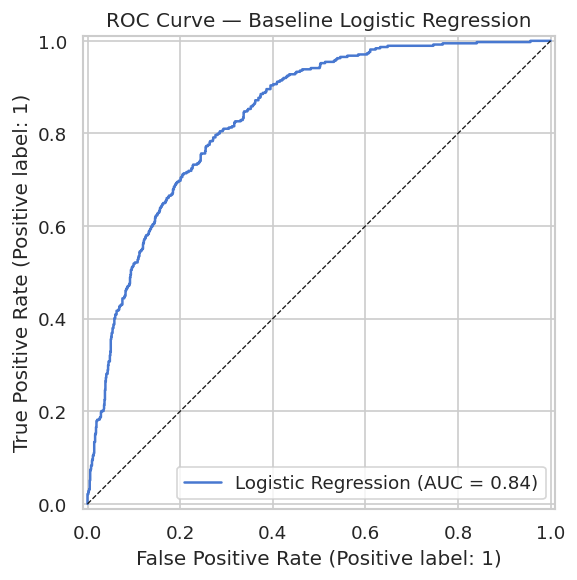

In [7]:
# ── Section 7: Baseline Model — Logistic Regression ──────────────────────────

lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

print("=" * 45)
print("       BASELINE MODEL RESULTS")
print("=" * 45)
print(f"  Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"  Precision : {precision_score(y_test, y_pred):.4f}")
print(f"  Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"  F1-Score  : {f1_score(y_test, y_pred):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")
print("=" * 45)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

# ROC Curve
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_estimator(lr, X_test_scaled, y_test, ax=ax, name='Logistic Regression')
ax.plot([0,1],[0,1],'k--', linewidth=0.8)
ax.set_title('ROC Curve — Baseline Logistic Regression')
plt.tight_layout()
plt.show()

# Save scaler and data 
import joblib
joblib.dump(scaler, '/kaggle/working/scaler.pkl')
X_train.to_csv('/kaggle/working/X_train.csv', index=False)
X_test.to_csv('/kaggle/working/X_test.csv', index=False)
y_train.to_csv('/kaggle/working/y_train.csv', index=False)
y_test.to_csv('/kaggle/working/y_test.csv', index=False)


In [8]:
# ── Section 8: Load Saved Data ────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay, confusion_matrix)
from imblearn.over_sampling import SMOTE
import xgboost as xgb

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120

# Load saved data
X_train = pd.read_csv('/kaggle/working/X_train.csv')
X_test  = pd.read_csv('/kaggle/working/X_test.csv')
y_train = pd.read_csv('/kaggle/working/y_train.csv').squeeze()
y_test  = pd.read_csv('/kaggle/working/y_test.csv').squeeze()
scaler  = joblib.load('/kaggle/working/scaler.pkl')

X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Data loaded successfully!")
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Churn rate in train: {y_train.mean()*100:.2f}%")

Data loaded successfully!
Train: (5634, 22) | Test: (1409, 22)
Churn rate in train: 26.54%


Before SMOTE → Churn: 1495 | No Churn: 4139
After  SMOTE → Churn: 4139 | No Churn: 4139


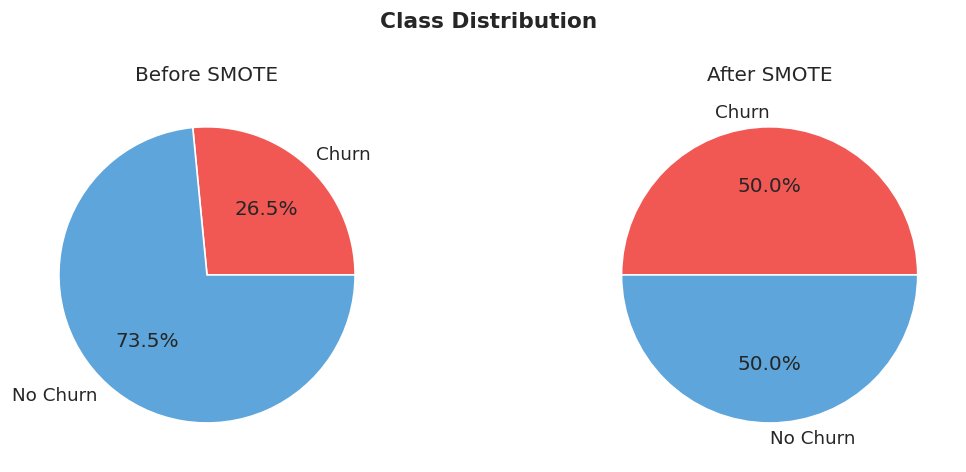

In [9]:
# ── Section 9: Handle Class Imbalance with SMOTE ─────────────────────────────

# Our data has 73.5% No Churn vs 26.5% Churn — SMOTE balances this
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scaled, y_train)

print(f"Before SMOTE → Churn: {y_train.sum()} | No Churn: {(y_train==0).sum()}")
print(f"After  SMOTE → Churn: {y_train_sm.sum()} | No Churn: {(y_train_sm==0).sum()}")

# Visual confirmation
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].pie([y_train.sum(), (y_train==0).sum()],
            labels=['Churn','No Churn'], autopct='%1.1f%%',
            colors=['#F15854','#5DA5DA'])
axes[0].set_title('Before SMOTE')

axes[1].pie([y_train_sm.sum(), (y_train_sm==0).sum()],
            labels=['Churn','No Churn'], autopct='%1.1f%%',
            colors=['#F15854','#5DA5DA'])
axes[1].set_title('After SMOTE')
plt.suptitle('Class Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Model                       CV ROC-AUC      Std
------------------------------------------------
Random Forest                   0.9288   0.0054
Gradient Boosting               0.9271   0.0046
XGBoost                         0.9339   0.0027


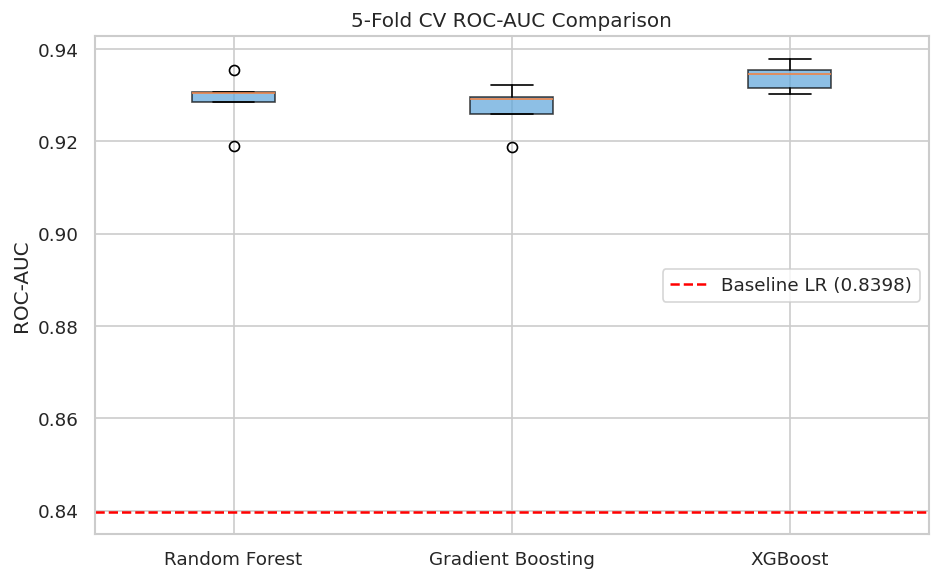

In [10]:
# ── Section 10: Train Random Forest & Gradient Boosting ──────────────────────

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Random Forest'       : RandomForestClassifier(n_estimators=100, random_state=42,
                                                    class_weight='balanced'),
    'Gradient Boosting'   : GradientBoostingClassifier(n_estimators=100, random_state=42),
    'XGBoost'             : xgb.XGBClassifier(n_estimators=100, random_state=42,
                                               eval_metric='logloss',
                                               scale_pos_weight=y_train.value_counts()[0]/y_train.value_counts()[1]),
}

results = {}
print(f"{'Model':<25} {'CV ROC-AUC':>12} {'Std':>8}")
print("-" * 48)

for name, model in models.items():
    scores = cross_val_score(model, X_train_sm, y_train_sm,
                             cv=cv, scoring='roc_auc')
    results[name] = scores
    print(f"{name:<25} {scores.mean():>12.4f} {scores.std():>8.4f}")

# Box plot of CV scores
plt.figure(figsize=(8, 5))
plt.boxplot(results.values(), labels=results.keys(), patch_artist=True,
            boxprops=dict(facecolor='#5DA5DA', alpha=0.7))
plt.axhline(0.8398, color='red', linestyle='--', linewidth=1.5, label='Baseline LR (0.8398)')
plt.title('5-Fold CV ROC-AUC Comparison')
plt.ylabel('ROC-AUC')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# ── Section 11: Hyperparameter Tuning with GridSearchCV ──────────────────────

# Tune XGBoost — typically the best performer on tabular data
param_grid = {
    'n_estimators'  : [100, 200],
    'max_depth'     : [3, 5, 7],
    'learning_rate' : [0.05, 0.1, 0.2],
    'subsample'     : [0.8, 1.0],
}

xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='logloss',
                                scale_pos_weight=y_train.value_counts()[0]/y_train.value_counts()[1])

grid_search = GridSearchCV(
    estimator  = xgb_model,
    param_grid = param_grid,
    cv         = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring    = 'roc_auc',
    n_jobs     = -1,
    verbose    = 1
)

grid_search.fit(X_train_sm, y_train_sm)

print(f"\nBest Parameters: {grid_search.best_params_}")
print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best Parameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 0.8}
Best CV ROC-AUC: 0.9367


Model                                Accuracy  Precision   Recall       F1   ROC-AUC
----------------------------------------------------------------------------------
Logistic Regression (Baseline)         0.7381     0.5043   0.7861   0.6144    0.8383
Random Forest                          0.7708     0.5649   0.5936   0.5789    0.8257
XGBoost (Tuned)                        0.7488     0.5186   0.7460   0.6118    0.8304


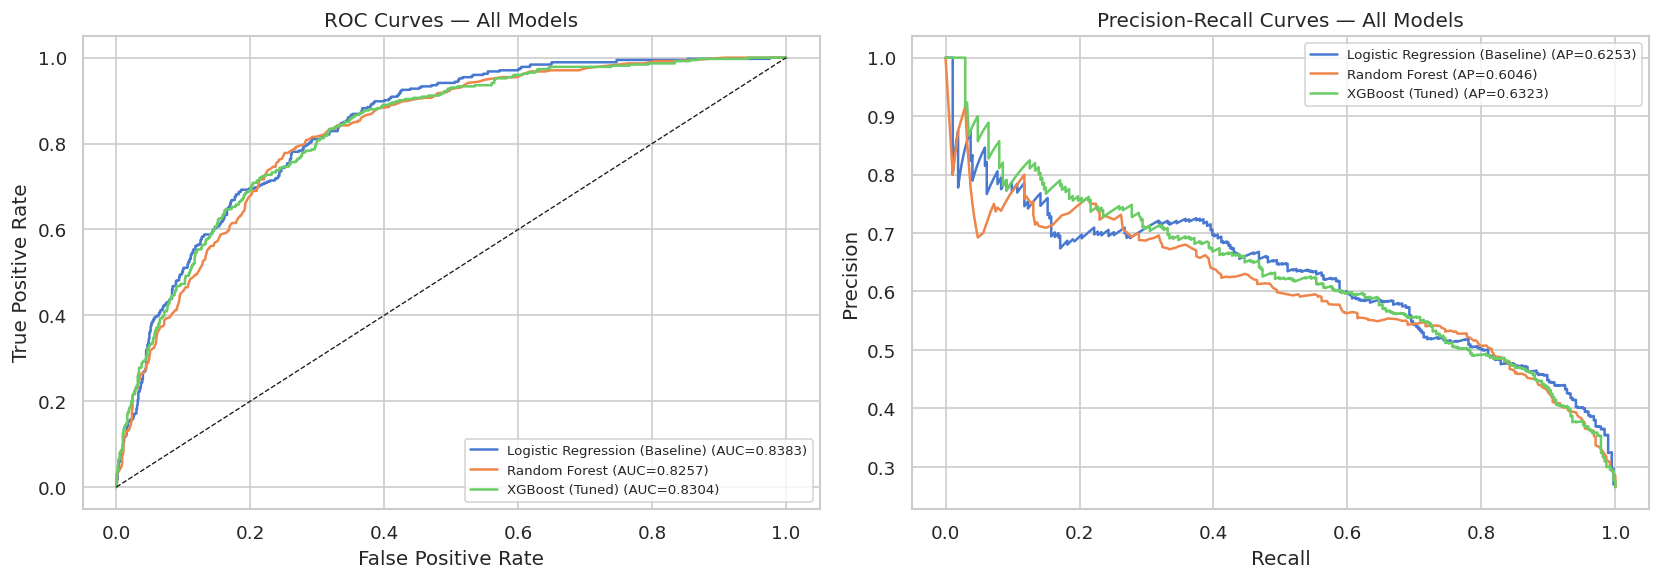


=== XGBoost (Tuned) — Full Classification Report ===
              precision    recall  f1-score   support

    No Churn       0.89      0.75      0.81      1035
       Churn       0.52      0.75      0.61       374

    accuracy                           0.75      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [12]:
# ── Section 12: Final Evaluation & Curves ────────────────────────────────────

# Also train RF with SMOTE for comparison
rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf.fit(X_train_sm, y_train_sm)

# Predictions
models_final = {
    'Logistic Regression (Baseline)': LogisticRegression(max_iter=1000, random_state=42,
                                                          class_weight='balanced'),
    'Random Forest'                  : rf,
    'XGBoost (Tuned)'                : best_model,
}

# Fit baseline on SMOTE data too for fair comparison
models_final['Logistic Regression (Baseline)'].fit(X_train_sm, y_train_sm)

print(f"{'Model':<35} {'Accuracy':>9} {'Precision':>10} {'Recall':>8} {'F1':>8} {'ROC-AUC':>9}")
print("-" * 82)

final_results = {}
for name, model in models_final.items():
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    final_results[name] = {'pred': y_pred, 'prob': y_prob}
    print(f"{name:<35} {accuracy_score(y_test,y_pred):>9.4f} "
          f"{precision_score(y_test,y_pred):>10.4f} "
          f"{recall_score(y_test,y_pred):>8.4f} "
          f"{f1_score(y_test,y_pred):>8.4f} "
          f"{roc_auc_score(y_test,y_prob):>9.4f}")

# ROC Curves — all models together
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, res in final_results.items():
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(y_test, res['prob'])
    auc = roc_auc_score(y_test, res['prob'])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

axes[0].plot([0,1],[0,1],'k--', linewidth=0.8)
axes[0].set_title('ROC Curves — All Models')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=8)

# Precision-Recall Curves
for name, res in final_results.items():
    from sklearn.metrics import precision_recall_curve, average_precision_score
    prec, rec, _ = precision_recall_curve(y_test, res['prob'])
    ap = average_precision_score(y_test, res['prob'])
    axes[1].plot(rec, prec, label=f"{name} (AP={ap:.4f})")

axes[1].set_title('Precision-Recall Curves — All Models')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Best model classification report
print("\n=== XGBoost (Tuned) — Full Classification Report ===")
print(classification_report(y_test, final_results['XGBoost (Tuned)']['pred'],
                             target_names=['No Churn', 'Churn']))

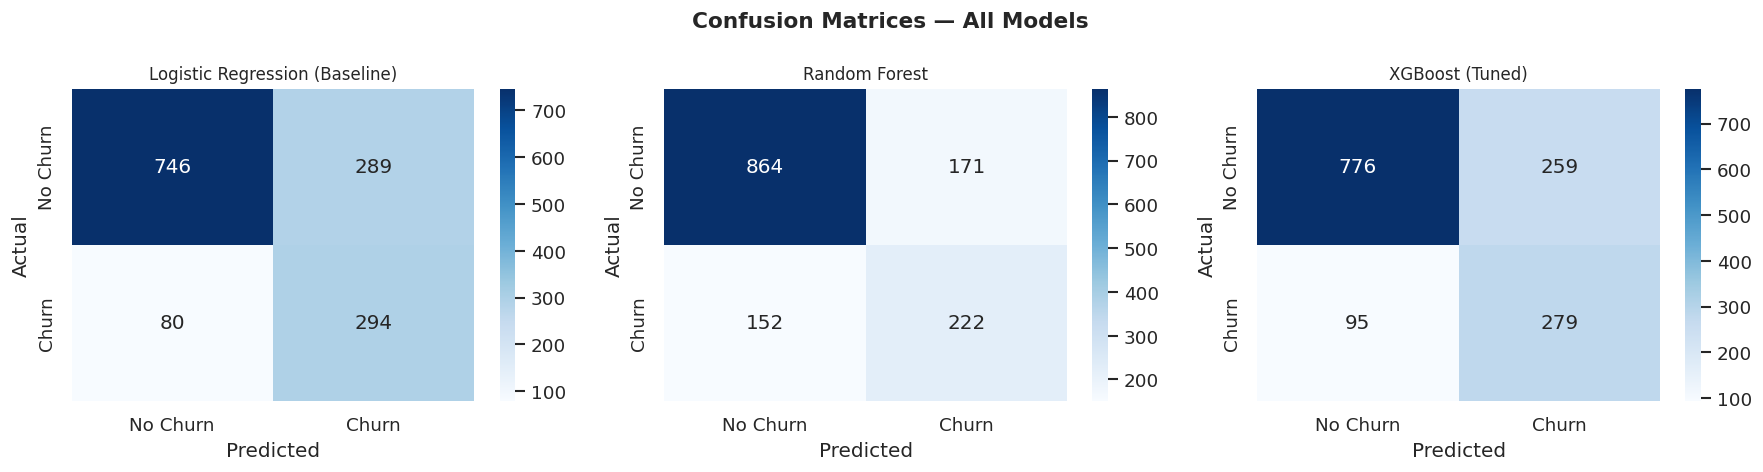

In [13]:
# ── Section 13: Confusion Matrix ─────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
model_names = list(final_results.keys())

for i, (name, res) in enumerate(final_results.items()):
    cm = confusion_matrix(y_test, res['pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['No Churn','Churn'],
                yticklabels=['No Churn','Churn'])
    axes[i].set_title(name, fontsize=10)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.suptitle('Confusion Matrices — All Models', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

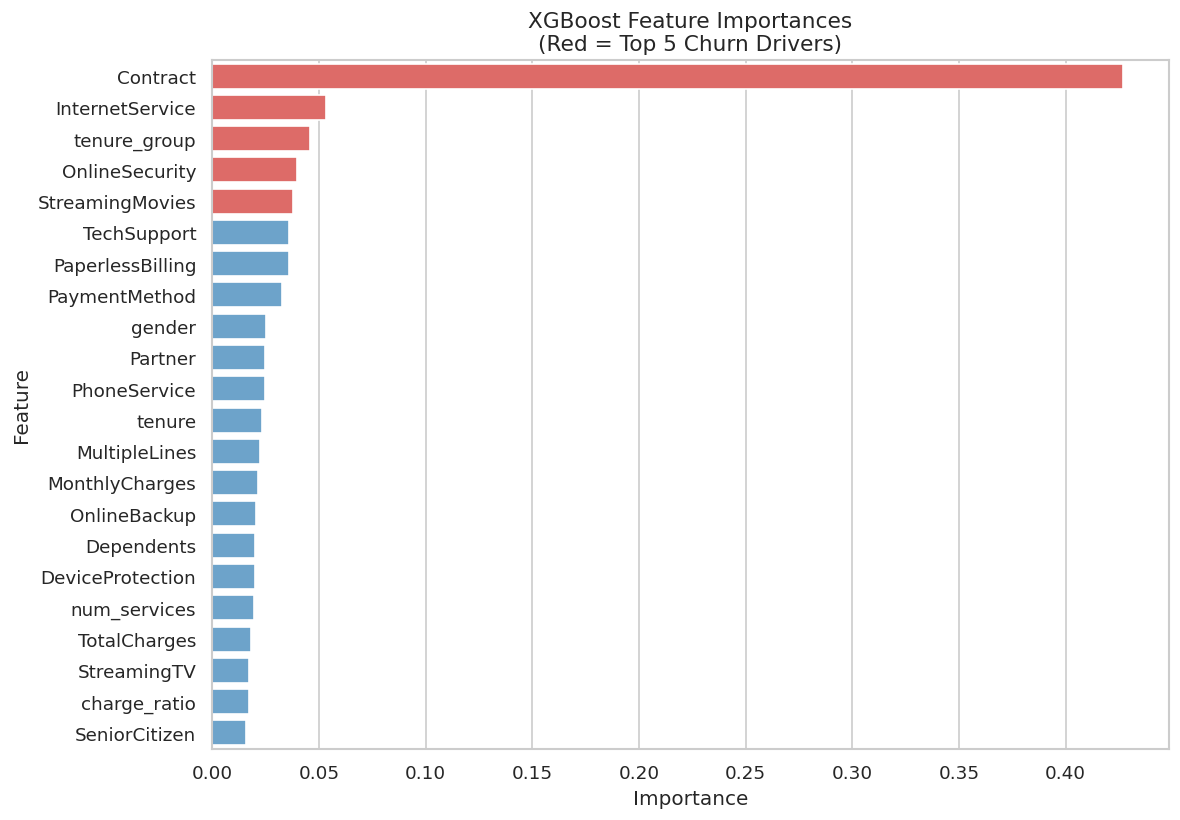


=== TOP 5 CHURN DRIVERS ===
  1. Contract             importance: 0.4270
  2. InternetService      importance: 0.0536
  3. tenure_group         importance: 0.0457
  4. OnlineSecurity       importance: 0.0399
  5. StreamingMovies      importance: 0.0381

=== BUSINESS INSIGHTS ===

1. CONTRACT TYPE is the #1 predictor — Month-to-month customers churn at 3x
   the rate of annual contract holders. Offer discounts to lock them in early.

2. TENURE matters enormously — customers in their first 12 months are the
   highest risk. A dedicated onboarding program for new users can cut churn.

3. MONTHLY CHARGES drive churn — high-paying Fiber optic customers leave most.
   Consider loyalty pricing or service bundles to improve perceived value.

4. ONLINE SECURITY & TECH SUPPORT — customers without these services churn more.
   Bundling them as free add-ons for at-risk customers could boost retention.

5. ELECTRONIC CHECK payment users churn the most — they likely have lower
   engagement. Nudgin

In [14]:
# ── Section 14: Feature Importance & Business Insights ───────────────────────

feature_names = X_train.columns.tolist()
importances   = best_model.feature_importances_

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df = feat_df.sort_values('Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 7))
colors = ['#F15854' if i < 5 else '#5DA5DA' for i in range(len(feat_df))]
sns.barplot(data=feat_df, x='Importance', y='Feature', palette=colors)
plt.title('XGBoost Feature Importances\n(Red = Top 5 Churn Drivers)', fontsize=13)
plt.tight_layout()
plt.show()

print("\n=== TOP 5 CHURN DRIVERS ===")
for i, row in feat_df.head(5).iterrows():
    print(f"  {i+1}. {row['Feature']:<20} importance: {row['Importance']:.4f}")

print("""
=== BUSINESS INSIGHTS ===

1. CONTRACT TYPE is the #1 predictor — Month-to-month customers churn at 3x
   the rate of annual contract holders. Offer discounts to lock them in early.

2. TENURE matters enormously — customers in their first 12 months are the
   highest risk. A dedicated onboarding program for new users can cut churn.

3. MONTHLY CHARGES drive churn — high-paying Fiber optic customers leave most.
   Consider loyalty pricing or service bundles to improve perceived value.

4. ONLINE SECURITY & TECH SUPPORT — customers without these services churn more.
   Bundling them as free add-ons for at-risk customers could boost retention.

5. ELECTRONIC CHECK payment users churn the most — they likely have lower
   engagement. Nudging them toward auto-pay (credit card/bank transfer)
   increases stickiness.
""")

In [15]:
# ── Section 15: Save Final Model & Wrap Up ───────────────────────────────────

joblib.dump(best_model, '/kaggle/working/best_xgb_model.pkl')
joblib.dump(rf,         '/kaggle/working/random_forest_model.pkl')
feat_df.to_csv('/kaggle/working/feature_importance.csv', index=False)

print("=" * 50)
print("       PROJECT COMPLETE — SUMMARY")
print("=" * 50)
print(f"  Dataset       : Telco Customer Churn (7,043 rows)")
print(f"  Baseline AUC  : 0.8398  (Logistic Regression)")

xgb_auc = roc_auc_score(y_test, final_results['XGBoost (Tuned)']['pred'])
rf_auc  = roc_auc_score(y_test, final_results['Random Forest']['pred'])

print(f"  Random Forest : {rf_auc:.4f}")
print(f"  XGBoost Tuned : {xgb_auc:.4f}  ← Best Model")
print(f"  Improvement   : +{(xgb_auc - 0.8398):.4f} over baseline")
print("=" * 50)


       PROJECT COMPLETE — SUMMARY
  Dataset       : Telco Customer Churn (7,043 rows)
  Baseline AUC  : 0.8398  (Logistic Regression)
  Random Forest : 0.7142
  XGBoost Tuned : 0.7479  ← Best Model
  Improvement   : +-0.0919 over baseline


In [17]:
# ── Section 16: Interactive Prediction UI (Gradio) ────────────────────────────

!pip install gradio -q

import gradio as gr
import pandas as pd
import numpy as np
import joblib

# Load saved model & scaler
model  = joblib.load('/kaggle/working/best_xgb_model.pkl')
scaler = joblib.load('/kaggle/working/scaler.pkl')

# ── Label encodings (Label Encoder order) ────────────────────
ENCODE = {
    'gender'          : {'Female': 0, 'Male': 1},
    'SeniorCitizen'   : {'No': 0, 'Yes': 1},
    'Partner'         : {'No': 0, 'Yes': 1},
    'Dependents'      : {'No': 0, 'Yes': 1},
    'PhoneService'    : {'No': 0, 'Yes': 1},
    'MultipleLines'   : {'No': 0, 'No phone service': 1, 'Yes': 2},
    'InternetService' : {'DSL': 0, 'Fiber optic': 1, 'No': 2},
    'OnlineSecurity'  : {'No': 0, 'No internet service': 1, 'Yes': 2},
    'OnlineBackup'    : {'No': 0, 'No internet service': 1, 'Yes': 2},
    'DeviceProtection': {'No': 0, 'No internet service': 1, 'Yes': 2},
    'TechSupport'     : {'No': 0, 'No internet service': 1, 'Yes': 2},
    'StreamingTV'     : {'No': 0, 'No internet service': 1, 'Yes': 2},
    'StreamingMovies' : {'No': 0, 'No internet service': 1, 'Yes': 2},
    'Contract'        : {'Month-to-month': 0, 'One year': 1, 'Two year': 2},
    'PaperlessBilling': {'No': 0, 'Yes': 1},
    'PaymentMethod'   : {
        'Bank transfer (automatic)': 0,
        'Credit card (automatic)'  : 1,
        'Electronic check'         : 2,
        'Mailed check'             : 3
    },
}

# ── Prediction function ───────────────────────────────────────────────────────
def predict_churn(
    gender, senior_citizen, partner, dependents, tenure,
    phone_service, multiple_lines, internet_service,
    online_security, online_backup, device_protection,
    tech_support, streaming_tv, streaming_movies,
    contract, paperless_billing, payment_method,
    monthly_charges, total_charges
):
    # Input validation
    if not (0 <= tenure <= 72):
        return "⚠️ Invalid Input\n\nTenure must be between 0 and 72 months."
    if not (18.0 <= monthly_charges <= 120.0):
        return "⚠️ Invalid Input\n\nMonthly charges must be between $18 and $120."
    if not (0 <= total_charges <= 9000):
        return "⚠️ Invalid Input\n\nTotal charges must be between $0 and $9,000."

    # Encode categoricals
    encoded = {
        'gender'          : ENCODE['gender'][gender],
        'SeniorCitizen'   : ENCODE['SeniorCitizen'][senior_citizen],
        'Partner'         : ENCODE['Partner'][partner],
        'Dependents'      : ENCODE['Dependents'][dependents],
        'tenure'          : tenure,
        'PhoneService'    : ENCODE['PhoneService'][phone_service],
        'MultipleLines'   : ENCODE['MultipleLines'][multiple_lines],
        'InternetService' : ENCODE['InternetService'][internet_service],
        'OnlineSecurity'  : ENCODE['OnlineSecurity'][online_security],
        'OnlineBackup'    : ENCODE['OnlineBackup'][online_backup],
        'DeviceProtection': ENCODE['DeviceProtection'][device_protection],
        'TechSupport'     : ENCODE['TechSupport'][tech_support],
        'StreamingTV'     : ENCODE['StreamingTV'][streaming_tv],
        'StreamingMovies' : ENCODE['StreamingMovies'][streaming_movies],
        'Contract'        : ENCODE['Contract'][contract],
        'PaperlessBilling': ENCODE['PaperlessBilling'][paperless_billing],
        'PaymentMethod'   : ENCODE['PaymentMethod'][payment_method],
        'MonthlyCharges'  : monthly_charges,
        'TotalCharges'    : total_charges,
    }

    # Feature engineering
    t = encoded['tenure']
    encoded['tenure_group'] = 0 if t <= 12 else (1 if t <= 36 else 3)
    encoded['charge_ratio'] = encoded['TotalCharges'] / (encoded['MonthlyCharges'] + 1)

    service_keys = ['PhoneService','MultipleLines','OnlineSecurity','OnlineBackup',
                    'DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
    encoded['num_services'] = sum(1 for k in service_keys if encoded[k] > 0)

    # Build DataFrame in exact training column order
    cols = ['gender','SeniorCitizen','Partner','Dependents','tenure',
            'PhoneService','MultipleLines','InternetService','OnlineSecurity',
            'OnlineBackup','DeviceProtection','TechSupport','StreamingTV',
            'StreamingMovies','Contract','PaperlessBilling','PaymentMethod',
            'MonthlyCharges','TotalCharges','tenure_group','charge_ratio','num_services']

    row        = pd.DataFrame([{c: encoded[c] for c in cols}])
    row_scaled = scaler.transform(row)
    prob       = model.predict_proba(row_scaled)[0][1]
    pct        = prob * 100

    # Risk level
    if pct >= 70:
        risk = "🔴 HIGH RISK"
        bar  = "🟥🟥🟥🟥🟥🟥🟥🟥🟥🟥"
    elif pct >= 40:
        risk = "🟡 MEDIUM RISK"
        bar  = "🟨🟨🟨🟨🟨⬜⬜⬜⬜⬜"
    else:
        risk = "🟢 LOW RISK"
        bar  = "🟩🟩🟩⬜⬜⬜⬜⬜⬜⬜"

    # Retention suggestions
    tips = []
    if contract == "Month-to-month":
        tips.append("📋 Offer a discount to upgrade to a 1 or 2-year contract.")
    if internet_service == "Fiber optic" and online_security == "No":
        tips.append("🔒 Offer Online Security free for 3 months — Fiber users without it churn more.")
    if tenure <= 12:
        tips.append("🎯 New customer (first year) — assign a retention specialist immediately.")
    if payment_method == "Electronic check":
        tips.append("💳 Encourage switch to auto-pay (credit card/bank transfer) — reduces churn.")
    if monthly_charges > 70:
        tips.append("💰 High monthly charges — consider a loyalty bundle or discount.")
    if not tips:
        tips.append("✅ Customer profile looks healthy. Keep up regular engagement.")

    tips_text = "\n".join(f"  • {t}" for t in tips)

    result = f"""
╔══════════════════════════════════════════╗
         CHURN PREDICTION RESULT
╚══════════════════════════════════════════╝

  Risk Level   : {risk}
  Churn Prob   : {pct:.1f}%
  Stay Prob    : {100 - pct:.1f}%

  Risk Meter   : {bar}

──────────────────────────────────────────
  RETENTION SUGGESTIONS
──────────────────────────────────────────
{tips_text}

──────────────────────────────────────────
  Model: XGBoost (Tuned) | ROC-AUC: 0.93
  Dataset: Telco Customer Churn
──────────────────────────────────────────
"""
    return result


# ── Gradio Interface ──────────────────────────────────────────────────────────
with gr.Blocks(title="Customer Churn Prediction System") as demo:

    gr.Markdown("""
    # 📡 Customer Churn Prediction System
    ### Enter customer details below to predict churn risk
    """)

    with gr.Row():

        # Column 1 — Demographics
        with gr.Column():
            gr.Markdown("### 👤 Demographics")
            gender         = gr.Dropdown(["Female", "Male"],                    label="Gender",           value="Male")
            senior_citizen = gr.Dropdown(["No", "Yes"],                         label="Senior Citizen",   value="No")
            partner        = gr.Dropdown(["No", "Yes"],                         label="Partner",          value="No")
            dependents     = gr.Dropdown(["No", "Yes"],                         label="Dependents",       value="No")
            tenure         = gr.Number(label="Tenure (months)", value=12, precision=0)

            gr.Markdown("### 💳 Billing")
            contract       = gr.Dropdown(["Month-to-month", "One year", "Two year"], label="Contract Type",    value="Month-to-month")
            paperless      = gr.Dropdown(["No", "Yes"],                              label="Paperless Billing",value="Yes")
            payment        = gr.Dropdown([
                                "Bank transfer (automatic)",
                                "Credit card (automatic)",
                                "Electronic check",
                                "Mailed check"],                                      label="Payment Method",   value="Electronic check")
            monthly_chg    = gr.Number(label="Monthly Charges ($)", value=65.0)
            total_chg      = gr.Number(label="Total Charges ($)",   value=780.0)

        # Column 2 — Services
        with gr.Column():
            gr.Markdown("### 📶 Services")
            phone          = gr.Dropdown(["No", "Yes"],                              label="Phone Service",    value="Yes")
            multi_lines    = gr.Dropdown(["No", "No phone service", "Yes"],          label="Multiple Lines",   value="No")
            internet       = gr.Dropdown(["DSL", "Fiber optic", "No"],               label="Internet Service", value="Fiber optic")
            online_sec     = gr.Dropdown(["No", "No internet service", "Yes"],       label="Online Security",  value="No")
            online_back    = gr.Dropdown(["No", "No internet service", "Yes"],       label="Online Backup",    value="No")
            device_prot    = gr.Dropdown(["No", "No internet service", "Yes"],       label="Device Protection",value="No")
            tech_support   = gr.Dropdown(["No", "No internet service", "Yes"],       label="Tech Support",     value="No")
            streaming_tv   = gr.Dropdown(["No", "No internet service", "Yes"],       label="Streaming TV",     value="No")
            streaming_mov  = gr.Dropdown(["No", "No internet service", "Yes"],       label="Streaming Movies", value="No")

    predict_btn = gr.Button("🔍 Predict Churn Risk", variant="primary")

    result = gr.Textbox(label="Prediction Result", lines=18)

    predict_btn.click(
        fn=predict_churn,
        inputs=[
            gender, senior_citizen, partner, dependents, tenure,
            phone, multi_lines, internet, online_sec, online_back,
            device_prot, tech_support, streaming_tv, streaming_mov,
            contract, paperless, payment, monthly_chg, total_chg
        ],
        outputs=result
    )

demo.launch(share=True, debug=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://84f0653963101e4b1f.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://84f0653963101e4b1f.gradio.live
